# The problem

Mobile money services serve millions of people. Scammers trick users into sending money (fake agent calls, OTP and PIN theft) or take over accounts and empty them. The money is usually moved and cashed out within minutes, so a fraud detected after the transfer is a fraud that already succeeded.

To protect users, a provider needs to decide while the transaction is happening:

Risk	Decision	What the user sees
Low	    APPROVE	    Nothing — the transfer goes through
Medium	STEP_UP	    An extra PIN or confirmation request
High	 HOLD	    The transfer is paused and the user gets an SMS warning

Two things make this hard:
Time: the decision has to be made in milliseconds, inside the transaction.
Balance: blocking too many genuine transfers hurts the people we want to protect, so every false alarm has a cost.


# Part 1: Analysis

In [1]:
import os, sys, glob, time, math, json, platform, warnings
import numpy as np
import pandas as pd
import sklearn, joblib
import matplotlib.pyplot as plt
%matplotlib inline
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FRAUD_C, GENUINE_C = "tab:red", "tab:green"
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             confusion_matrix, f1_score)
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, IsolationForest
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, precision_recall_curve
warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30)
try:
    import lightgbm as lgb
    HAS_LGB = True
except Exception:
    HAS_LGB = False

print(f"Platform : {platform.machine()} ({platform.system()})   <- s390x = IBM Z / LinuxONE")
print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | scikit-learn {sklearn.__version__}")
print("Model engine:", f"LightGBM {lgb.__version__}" if HAS_LGB else
      "scikit-learn HistGradientBoosting (LightGBM-style; lightgbm not installed)")

# ---------------- configuration ----------------
DATA_DIR   = "data"
TEST_FRAC  = 0.30       # last 30% of TRANSFER/CASH_OUT rows = test (the same test set Kopylov used)
VALID_FRAC = 0.10       # the 10% just before it = used only to choose decision thresholds
CURRENCY   = ""         # PaySim does not state a currency; 
COST_STEP_UP = 20       # cost of asking a genuine customer for an extra PIN
COST_HOLD    = 300      # cost of wrongly holding a genuine transfer (support call, lost trust)
MAX_HOLD_RATE    = 0.001  # friction budget: hold at most 1 in 1,000 genuine transactions
MAX_STEP_UP_RATE = 0.01   # and ask at most 1 in 100 genuine customers for a PIN
STREAM_DEMO_N = 30000   # transactions replayed one by one in the live demo
SEED = 42
os.makedirs("artifacts", exist_ok=True)

Platform : s390x (Linux)   <- s390x = IBM Z / LinuxONE
Python 3.12.15 | numpy 2.0.2 | pandas 3.0.6 | scikit-learn 1.9.0
Model engine: LightGBM 4.7.0


# Analysing the Data
   
PaySim is a synthetic dataset generated from one month of real mobile money logs from an African country (Kaggle: https://www.kaggle.com/datasets/ealaxi/paysim1). It has about 6.3 million transactions over 744 hours.


In [2]:
df = pd.read_csv('PS_20174392719_1491204439457_log.csv')
# Load Data in

In [3]:
df[:1]

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0


In [4]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


From above we can see step runs from 1 to 743, the hours of the month.

The fraud rate (isFraud mean) is 0.129%, very rare.
isFlaggedFraud mean is about 0.0000025, so the existing rule flags almost nothing.
Amounts are very skewed: median about 75,000 but maximum about 92 million.

Many balances are 0. At least 25% of oldbalanceOrg values are zero, and so are half of newbalanceOrig.

          transactions  share %
type                           
CASH_OUT       2237500     35.2
PAYMENT        2151495     33.8
CASH_IN        1399284     22.0
TRANSFER        532909      8.4
DEBIT            41432      0.7


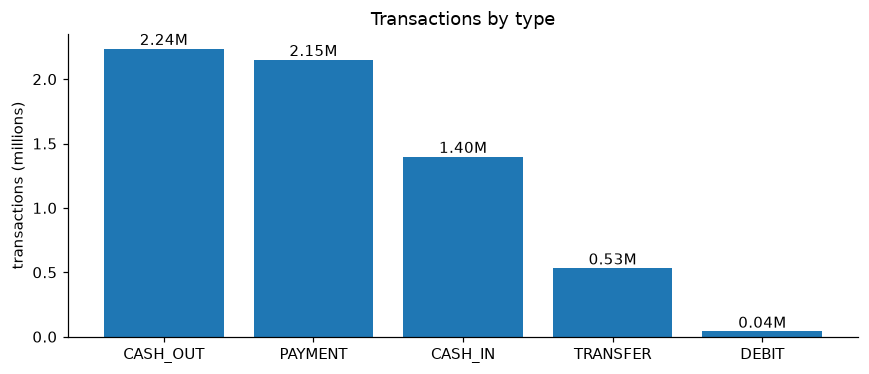

In [5]:
type_counts = df["type"].value_counts()
share = (type_counts / len(df) * 100).round(1)
print(pd.DataFrame({"transactions": type_counts, "share %": share}).to_string())

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(type_counts.index.astype(str), type_counts.values / 1e6, color="tab:blue")
for i, v in enumerate(type_counts.values):
    ax.text(i, v / 1e6, f"{v / 1e6:.2f}M", ha="center", va="bottom")
ax.set_ylabel("transactions (millions)"); ax.set_title("Transactions by type")
plt.tight_layout(); plt.show()

From the above figure we can see CASH_OUT and PAYMENT are the most common transaction types, followed by CASH_IN. TRANSFER is much less common,
and DEBIT is the rarest.

In [6]:
df.groupby('type')[['isFraud','isFlaggedFraud']].sum()

,isFraud,isFlaggedFraud
type,,
CASH_IN,0,0
CASH_OUT,4116,0
DEBIT,0,0
PAYMENT,0,0
TRANSFER,4097,16


In [7]:
by_type = df.groupby("type", observed=True)["isFraud"].agg(transactions="size", fraud="sum")
by_type["fraud rate"] = (by_type["fraud"] / by_type["transactions"]).map("{:.3%}".format)
by_type["1 fraud in every"] = (by_type["transactions"] / by_type["fraud"].replace(0, np.nan)).round(0)
print(by_type.to_string(), "\n")

tc = df["type"].isin(["TRANSFER", "CASH_OUT"])
print(f"TRANSFER + CASH_OUT: {tc.sum():,} transactions ({tc.mean():.1%} of all), "
      f"containing {int(df.loc[tc, 'isFraud'].sum()):,} of {int(df.isFraud.sum()):,} frauds")
print(f"Fraud rate overall: {df.isFraud.mean():.3%}  ->  within TRANSFER + CASH_OUT: {df.loc[tc, 'isFraud'].mean():.3%}")

          transactions  fraud fraud rate  1 fraud in every
type                                                      
CASH_IN        1399284      0     0.000%               NaN
CASH_OUT       2237500   4116     0.184%             544.0
DEBIT            41432      0     0.000%               NaN
PAYMENT        2151495      0     0.000%               NaN
TRANSFER        532909   4097     0.769%             130.0 

TRANSFER + CASH_OUT: 2,770,409 transactions (43.5% of all), containing 8,213 of 8,213 frauds
Fraud rate overall: 0.129%  ->  within TRANSFER + CASH_OUT: 0.296%


Fraud happens only in TRANSFER and CASH_OUT, and the existing rule caught just 16 of 8,213 frauds. Which Scamshield is aiming to beat this number and catch fraud with higher accuracy.

In [8]:
print(f"Accuracy of a 'model' that always says NOT FRAUD: {1 - df.isFraud.mean():.4%}")

Accuracy of a 'model' that always says NOT FRAUD: 99.8709%


As the amount of fraud is significantly lower than the amount of transactions and transfers,etc a model that never flags any suspicious activity is already 99.87% accurate and thus catches zero frauds. So judging by accuracy only is useless here.

We will judge models by:
Area under the precision-recall curve: How well the model ranks frauds above genuine transactions;
Recall at a fixed precision: how much fraud is caught while keeping false alarms low;
Money saved vs. customers inconvenienced, which is what a provider actually cares about.

    

In [9]:
flag = df["isFlaggedFraud"] == 1
fraud = df["isFraud"] == 1
print(f"Transactions flagged by the existing rule: {flag.sum():,}")
print(f"  of which really fraud: {(flag & fraud).sum():,}  (precision {(flag & fraud).sum() / max(flag.sum(), 1):.0%})")
print(f"Frauds caught by the rule: {(flag & fraud).sum():,} of {fraud.sum():,}  (recall {(flag & fraud).sum() / fraud.sum():.2%})")
print(f"Fraud value caught: {df.loc[flag & fraud, 'amount'].sum() / df.loc[fraud, 'amount'].sum():.2%} of all fraud money\n")
print("Flagged transactions by type:", df.loc[flag, "type"].value_counts()[lambda s: s > 0].to_dict())
print(f"Smallest flagged amount: {df.loc[flag, 'amount'].min():,.0f}")
big_tr = (df["type"] == "TRANSFER") & (df["amount"] > 200_000)
print(f"TRANSFERs over 200,000: {big_tr.sum():,}, of which flagged: {(big_tr & flag).sum():,}")

Transactions flagged by the existing rule: 16
  of which really fraud: 16  (precision 100%)
Frauds caught by the rule: 16 of 8,213  (recall 0.19%)
Fraud value caught: 0.65% of all fraud money

Flagged transactions by type: {'TRANSFER': 16}
Smallest flagged amount: 353,874
TRANSFERs over 200,000: 409,110, of which flagged: 16


In [10]:
df.groupby('type')['amount'].mean()

type
CASH_IN     168920.242004
CASH_OUT    176273.964346
DEBIT         5483.665314
PAYMENT      13057.604660
TRANSFER    910647.009645
Name: amount, dtype: float64

TRANSFERs average about 910,000, roughly five times larger than CASH_OUTs and seventy times larger than PAYMENTs. Fraud only occurs in TRANSFER and CASH_OUT, so large amounts are part of the fraud pattern. Amounts are very skewed, so the median is a better guide to a typical transaction than the mean.

In [11]:
by_type = df.groupby("type")["isFraud"].agg(rows="size", fraud="sum")
by_type["fraud rate"] = (by_type["fraud"] / by_type["rows"]).map("{:.3%}".format)
print(by_type.to_string(), "\n")
print(f"Accuracy of a 'model' that always says NOT FRAUD: {1 - df.isFraud.mean():.4%}")

             rows  fraud fraud rate
type                               
CASH_IN   1399284      0     0.000%
CASH_OUT  2237500   4116     0.184%
DEBIT       41432      0     0.000%
PAYMENT   2151495      0     0.000%
TRANSFER   532909   4097     0.769% 

Accuracy of a 'model' that always says NOT FRAUD: 99.8709%


In [12]:
pip install lightgbm

Note: you may need to restart the kernel to use updated packages.


In [13]:
pip install --upgrade pip

Note: you may need to restart the kernel to use updated packages.


# Analysing Transaction Amounts

All transactions by type:
            mean  median        max
type                               
CASH_IN  168,920 143,428  1,915,268
CASH_OUT 176,274 147,072 10,000,000
DEBIT      5,484   3,049    569,078
PAYMENT   13,058   9,482    238,638
TRANSFER 910,647 486,308 92,445,517 

TRANSFER and CASH_OUT, genuine (0) vs fraud (1):
                    count      mean  median        max
type     isFraud                                      
CASH_OUT 0        2233384   173,917 146,947  2,847,567
         1           4116 1,455,103 435,517 10,000,000
TRANSFER 0         528812   906,229 486,522 92,445,517
         1           4097 1,480,892 445,706 10,000,000


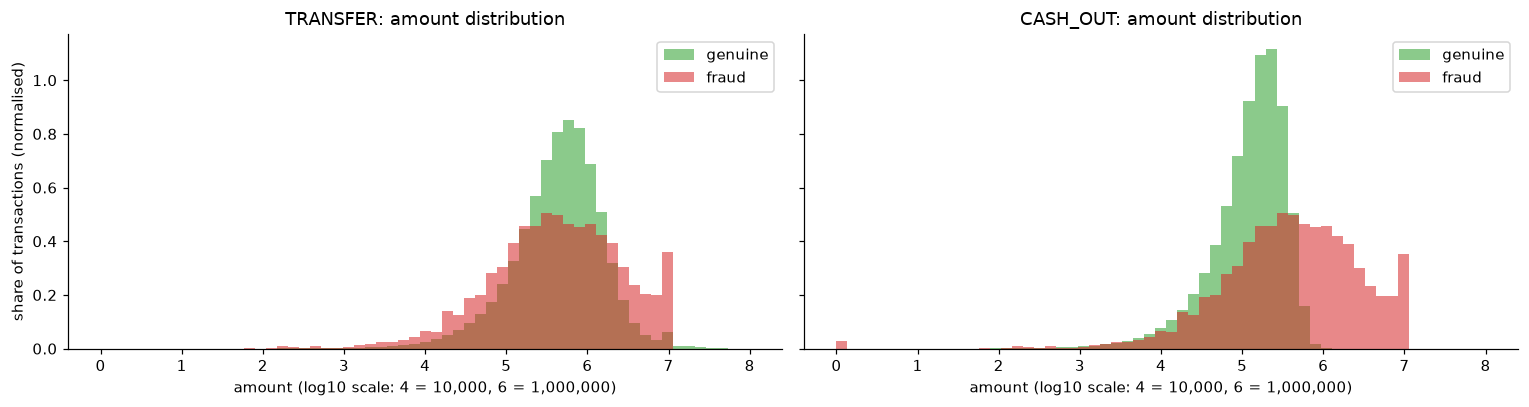

Largest fraud amount: 10,000,000; frauds at exactly this amount: 287
Genuine transactions above this amount: 2,443


In [14]:
amt = df.groupby("type", observed=True)["amount"].agg(["mean", "median", "max"])
print("All transactions by type:\n" + amt.to_string(float_format=lambda x: f"{x:,.0f}"), "\n")

sub = df[tc]
amt_f = sub.groupby(["type", "isFraud"], observed=True)["amount"].agg(["count", "mean", "median", "max"])
print("TRANSFER and CASH_OUT, genuine (0) vs fraud (1):\n" + amt_f.to_string(float_format=lambda x: f"{x:,.0f}"))


fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, t in zip(axes, ["TRANSFER", "CASH_OUT"]):
    s = sub[sub["type"] == t]
    g, f = np.log10(s.loc[s.isFraud == 0, "amount"] + 1), np.log10(s.loc[s.isFraud == 1, "amount"] + 1)
    bins = np.linspace(0, 8, 60)
    ax.hist(g, bins=bins, density=True, alpha=.55, color=GENUINE_C, label="genuine")
    ax.hist(f, bins=bins, density=True, alpha=.55, color=FRAUD_C, label="fraud")
    ax.set_title(f"{t}: amount distribution"); ax.set_xlabel("amount (log10 scale: 4 = 10,000, 6 = 1,000,000)")
    ax.legend()
axes[0].set_ylabel("share of transactions (normalised)")
plt.tight_layout(); plt.show()

cap = df.loc[fraud, "amount"].max()
print(f"Largest fraud amount: {cap:,.0f}; frauds at exactly this amount: {(df.loc[fraud, 'amount'] == cap).sum():,}")
print(f"Genuine transactions above this amount: {(df.loc[~fraud, 'amount'] > cap).sum():,}")

TRANSFERs are the largest transactions overall (median about 486,000, maximum about 92 million). Whether amount helps detect fraud depends on the type:

CASH_OUT: frauds are much larger than genuine cash-outs. The median fraud is about 3× the median genuine cash-out, and no genuine cash-out in the data exceeds about 2.85 million.
TRANSFER: fraud and genuine amounts overlap almost completely; the median fraud transfer is even slightly smaller than the median genuine one.

Fraud TRANSFERs and fraud CASH_OUTs have almost the same number, mean and median amount, which suggests frauds come as a transfer followed by a cash-out of the same amount. Amount is useful mainly for cash-outs and has to be combined with other signals.


# Analysing Timing Patterns

In [15]:
early = df["step"] <= 400
for name, mask in [("Hours 1-400  ", early), ("Hours 401-743", ~early)]:
    n, f = mask.sum(), int(df.loc[mask, "isFraud"].sum())
    print(f"{name}: {n:>9,} transactions, {f:>5,} frauds, fraud rate {f / n:.3%}, "
          f"{n / df.loc[mask, 'step'].nunique():>8,.0f} transactions per hour")

Hours 1-400  : 5,787,030 transactions, 4,477 frauds, fraud rate 0.077%,   14,468 transactions per hour
Hours 401-743:   575,590 transactions, 3,736 frauds, fraud rate 0.649%,    1,678 transactions per hour


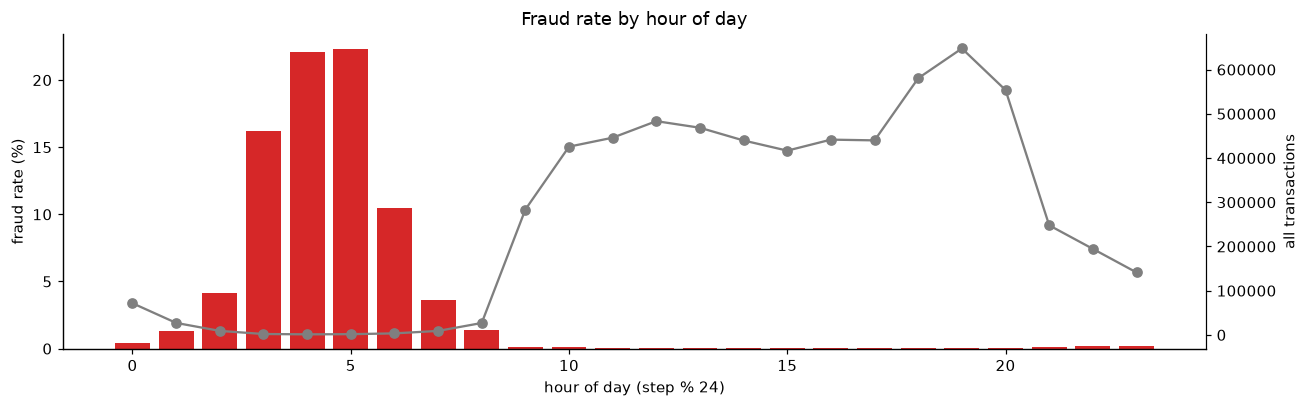

      transactions  fraud  fraud rate %
hour                                   
0            71587    300         0.419
1            27111    358         1.320
2             9018    372         4.125
3             2007    326        16.243
4             1241    274        22.079
5             1641    366        22.303
6             3420    358        10.468
7             8988    328         3.649
8            26915    368         1.367
9           283518    341         0.120
10          425729    375         0.088
11          445992    324         0.073
12          483418    339         0.070
13          468474    346         0.074
14          439653    353         0.080
15          416686    341         0.082
16          441612    345         0.078
17          439941    353         0.080
18          580509    343         0.059
19          647814    342         0.053
20          553728    340         0.061
21          247806    347         0.140
22          194555    351         0.180


In [16]:
df["hour"] = df["step"] % 24
by_hour = df.groupby("hour").agg(transactions=("isFraud", "size"), fraud=("isFraud", "sum"))
by_hour["fraud rate %"] = by_hour["fraud"] / by_hour["transactions"] * 100

fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(by_hour.index, by_hour["fraud rate %"], color=FRAUD_C, label="fraud rate")
ax.set_xlabel("hour of day (step % 24)"); ax.set_ylabel("fraud rate (%)")
ax2 = ax.twinx(); ax2.plot(by_hour.index, by_hour["transactions"], color="tab:gray", marker="o", label="all transactions")
ax2.set_ylabel("all transactions"); ax2.spines["right"].set_visible(True)
ax.set_title("Fraud rate by hour of day")
plt.tight_layout(); plt.show()
print(by_hour.round(3).to_string())

Fraud happens at an almost constant pace around the clock, between 274 and 375 frauds in every hour of the day, while genuine activity follows a strong daily cycle: about 648,000 transactions at 19:00 but only about 1,200 at 04:00. As a result, the fraud rate at night is extreme. Hour of day is therefore a very strong signal, and it is known the moment a transaction arrives, exactly what a real-time model needs. In real life fraud does tend to rise at night when victims are asleep, but the simulator’s perfectly even fraud pattern makes the effect much stronger than it would be in practice. ScamShield will use hour of day as one signal among several, not as a rule.

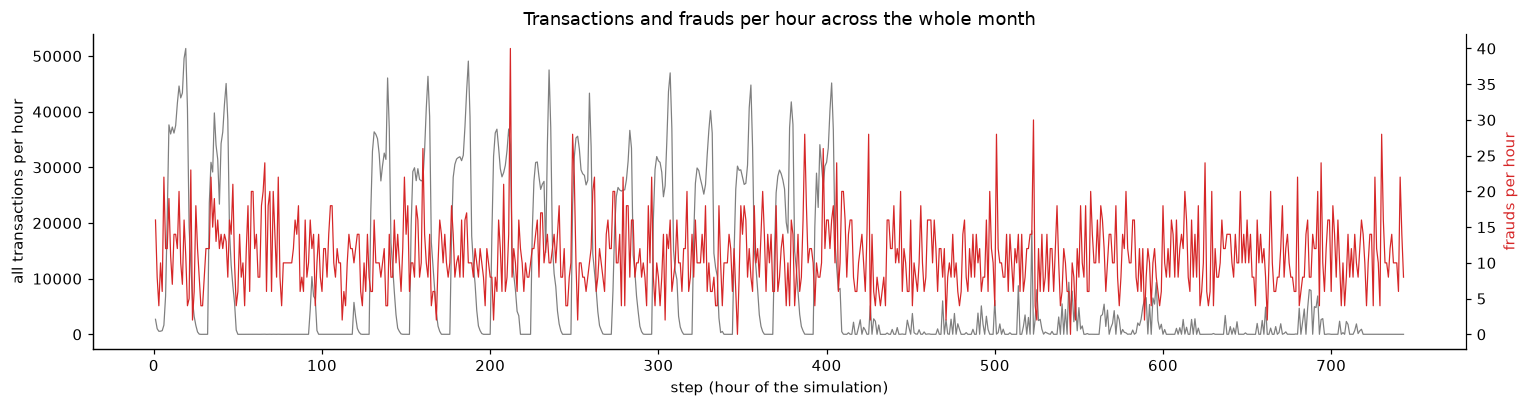

First half of the month: 3,186,492 transactions, 2,705 frauds
Second half of the month: 3,184,682 transactions, 5,518 frauds


In [17]:
per_step = df.groupby("step").agg(transactions=("isFraud", "size"), fraud=("isFraud", "sum"))
fig, ax = plt.subplots(figsize=(14, 3.8))
ax.plot(per_step.index, per_step["transactions"], color="tab:gray", lw=.8, label="all transactions")
ax.set_xlabel("step (hour of the simulation)"); ax.set_ylabel("all transactions per hour")
ax2 = ax.twinx(); ax2.plot(per_step.index, per_step["fraud"], color=FRAUD_C, lw=.8, label="fraud")
ax2.set_ylabel("frauds per hour", color=FRAUD_C); ax2.spines["right"].set_visible(True)
ax.set_title("Transactions and frauds per hour across the whole month")
plt.tight_layout(); plt.show()

half = df["step"].median()
print(f"First half of the month: {int(per_step.loc[:half, 'transactions'].sum()):,} transactions, "
      f"{int(per_step.loc[:half, 'fraud'].sum()):,} frauds")
print(f"Second half of the month: {int(per_step.loc[half:, 'transactions'].sum()):,} transactions, "
      f"{int(per_step.loc[half:, 'fraud'].sum()):,} frauds")

# Finding who Sends and Recieves 

In [18]:
orig_counts, dest_counts = df["nameOrig"].value_counts(), df["nameDest"].value_counts()
print(f"Unique senders  : {len(orig_counts):,}  | sending more than once: {(orig_counts > 1).sum():,} "
      f"({(orig_counts > 1).mean():.2%})")
print(f"Unique receivers: {len(dest_counts):,}  | receiving more than once: {(dest_counts > 1).sum():,} "
      f"({(dest_counts > 1).mean():.1%}); busiest receiver: {dest_counts.iloc[0]:,} transactions\n")

df["dest_kind"] = np.where(df["nameDest"].str.startswith("M"), "merchant", "customer")
print("Receiver kind by transaction type:")
print(pd.crosstab(df["type"], df["dest_kind"]).to_string())

Unique senders  : 6,353,307  | sending more than once: 9,298 (0.15%)
Unique receivers: 2,722,362  | receiving more than once: 459,658 (16.9%); busiest receiver: 113 transactions

Receiver kind by transaction type:
dest_kind  customer  merchant
type                         
CASH_IN     1399284         0
CASH_OUT    2237500         0
DEBIT         41432         0
PAYMENT           0   2151495
TRANSFER     532909         0


Senders almost never repeat: 6,353,307 unique senders for 6,362,620 transactions, and only 9,298 (0.15%) send more than once. Customer history can’t be built from senders.
Receivers repeat more, but not as much as I expected: 16.9% of receivers appear more than once, and the busiest gets 113 transactions. Receiver history will be useful but limited; most receivers are seen only once.
Merchants only receive PAYMENTs, and PAYMENTs never contain fraud. Every TRANSFER and CASH_OUT goes to a customer account, so “merchant vs customer” adds nothing once we keep only those two types.

In [19]:
fr_tr = df[fraud & (df["type"] == "TRANSFER")]
fr_co = df[fraud & (df["type"] == "CASH_OUT")]
linked_accounts = set(fr_tr["nameDest"]) & set(fr_co["nameOrig"])
print(f"Fraud TRANSFER receivers that later make a fraud CASH_OUT: {len(linked_accounts)} of {fr_tr['nameDest'].nunique():,}")

pairs = fr_tr.merge(fr_co, on=["step", "amount"], suffixes=("_tr", "_co"))
print(f"Fraud TRANSFERs with a fraud CASH_OUT of the same amount in the same hour: "
      f"{pairs['nameOrig_tr'].nunique():,} of {len(fr_tr):,}")


d = df.loc[tc, ["type", "nameDest", "isFraud"]].copy()
first_seen = ~df["nameDest"].duplicated()          
d["receiver_new"] = first_seen[tc].values
print("\nShare of transactions going to a receiver never seen before:")
print(d.groupby(["type", "isFraud"], observed=True)["receiver_new"].mean().unstack().rename(
      columns={0: "genuine", 1: "fraud"}).map("{:.1%}".format).to_string())

Fraud TRANSFER receivers that later make a fraud CASH_OUT: 0 of 4,097
Fraud TRANSFERs with a fraud CASH_OUT of the same amount in the same hour: 4,078 of 4,097

Share of transactions going to a receiver never seen before:
isFraud  genuine  fraud
type                   
CASH_OUT   14.6%  26.3%
TRANSFER   11.5%  99.9%


Frauds come in pairs: 4,078 of 4,097 fraud TRANSFERs (99.5%) are matched by a fraud CASH_OUT of exactly the same amount in the same hour, the classic pattern of moving stolen money out and then withdrawing it. However, the account receiving the transfer is never the account making the cash-out (0 of 4,097), so the money cannot be followed by account name in this dataset.

Fraud transfers go to brand-new accounts: 99.9% of fraud TRANSFERs go to a receiver that has never appeared before, compared with 11.5% of genuine transfers. For CASH_OUT the difference is smaller (26.3% vs 14.6%).

# State of the accounts Before and After Transfer

In [20]:
s = df[tc].copy()
EPS = 0.01
patterns = pd.DataFrame({
    "sender balance was zero before":         s["oldbalanceOrg"] <= EPS,
    "transfer empties the sender's account":  (s["oldbalanceOrg"] > EPS) & ((s["oldbalanceOrg"] - s["amount"]).abs() <= EPS),
    "amount larger than sender's balance":    s["amount"] > s["oldbalanceOrg"] + EPS,
    "receiver balance was zero before":       s["oldbalanceDest"] <= EPS,
})
before = patterns.groupby(s["isFraud"]).mean().T.rename(columns={0: "genuine", 1: "fraud"})
print("KNOWN BEFORE THE TRANSFER (share of transactions):")
print(before.map("{:.1%}".format).to_string())

after = pd.DataFrame({
    "sender balance changes by exactly the amount": ((s["oldbalanceOrg"] - s["newbalanceOrig"]).abs() - s["amount"]).abs() <= EPS,
    "receiver balance 0 before AND after (amount > 0)": (s["oldbalanceDest"] <= EPS) & (s["newbalanceDest"] <= EPS) & (s["amount"] > 0),
    "receiver balance changes by exactly the amount": ((s["newbalanceDest"] - s["oldbalanceDest"]) - s["amount"]).abs() <= EPS,
}).groupby(s["isFraud"]).mean().T.rename(columns={0: "genuine", 1: "fraud"})
print("KNOWN ONLY AFTER THE TRANSFER (share of transactions):")
print(after.map("{:.1%}".format).to_string())

KNOWN BEFORE THE TRANSFER (share of transactions):
isFraud                               genuine  fraud
sender balance was zero before          47.4%   0.5%
transfer empties the sender's account    0.0%  97.6%
amount larger than sender's balance     90.1%   0.4%
receiver balance was zero before        13.9%  65.2%
KNOWN ONLY AFTER THE TRANSFER (share of transactions):
isFraud                                          genuine  fraud
sender balance changes by exactly the amount        9.5%  99.5%
receiver balance 0 before AND after (amount > 0)    0.1%  49.6%
receiver balance changes by exactly the amount     79.8%  43.8%


97.6% of frauds empty the sender’s balance vs 0.0% of genuine, but 90.1% of genuine transactions exceed the sender’s balance. After-transfer balances separate fraud almost perfectly (e.g. receiver balance stays 0 in 49.6% of frauds vs 0.1% of genuine).

# Finding Correlation

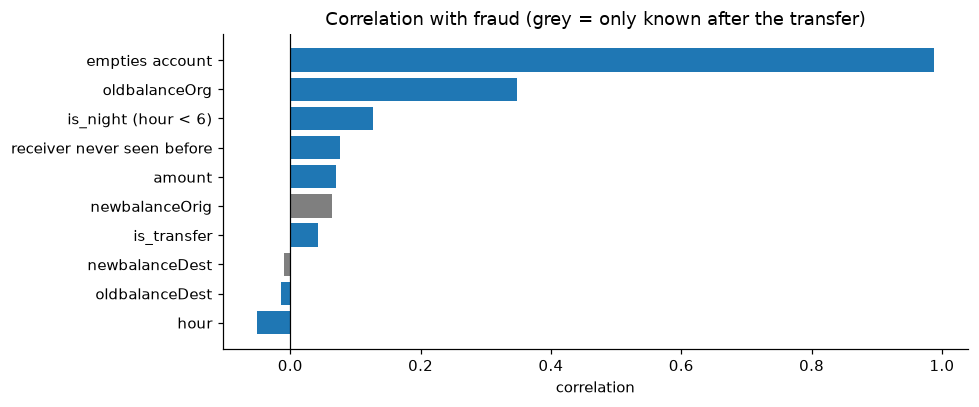

hour                         -0.051
oldbalanceDest               -0.015
newbalanceDest               -0.009
is_transfer                   0.042
newbalanceOrig                0.064
amount                        0.071
receiver never seen before    0.076
is_night (hour < 6)           0.127
oldbalanceOrg                 0.348
empties account               0.988


In [21]:
c = df.loc[tc, ["amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest", "hour", "isFraud"]].copy()
c["is_night (hour < 6)"] = (c["hour"] < 6).astype(int)
c["is_transfer"] = (df.loc[tc, "type"] == "TRANSFER").astype(int)
c["empties account"] = ((df.loc[tc, "oldbalanceOrg"] > 0.01) &
                        ((df.loc[tc, "oldbalanceOrg"] - df.loc[tc, "amount"]).abs() <= 0.01)).astype(int)
c["receiver never seen before"] = (~df["nameDest"].duplicated())[tc].astype(int).values
corr = c.corr(numeric_only=True)["isFraud"].drop("isFraud").sort_values()
known_after = {"newbalanceOrig", "newbalanceDest"}
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(corr.index, corr.values, color=["tab:gray" if k in known_after else "tab:blue" for k in corr.index])
ax.axvline(0, color="black", lw=.8)
ax.set_title("Correlation with fraud (grey = only known after the transfer)"); ax.set_xlabel("correlation")
plt.tight_layout(); plt.show()
print(corr.round(3).to_string())

“Transfer empties the sender’s account” correlates 0.988 with fraud. A model using it would look near-perfect, but 3.8 showed why: PaySim generates genuine amounts that ignore balances, while fraud amounts equal the victim’s balance. This is the strongest reason to also report ScamShield without balance features, as the realistic estimate.

Raw hour barely correlates with fraud (−0.05), but a night-time flag does (0.13), because fraud spikes at night rather than rising steadily through the day. Correlation only measures straight-line relationships.

“Receiver never seen before” correlates only 0.076, even though 99.9% of fraud transfers go to new receivers, because about 1 in 8 genuine transactions also do. It cannot separate fraud alone, but it greatly raises the odds. Fraud shows up in combinations (a large cash-out, at night, to a new receiver).

Part 2: Model and Real-Time Engine

In [22]:
pip install snapml

Note: you may need to restart the kernel to use updated packages.


In [23]:
warnings.filterwarnings("ignore")
try:
    import snapml; HAS_SNAP = True
except Exception:
    HAS_SNAP = False

cpu = open("/proc/cpuinfo").read().lower() if os.path.exists("/proc/cpuinfo") else ""
print(f"Platform: {platform.machine()} | Telum AI accelerator (NNPA): {'yes' if 'nnpa' in cpu else 'no'} | "
      f"IBM Snap ML: {'installed' if HAS_SNAP else 'not installed - run: pip install snapml'}")
print(f"Data: {len(df):,} transactions, {int(df.isFraud.sum()):,} frauds")

COST_STEP_UP, COST_HOLD = 20, 300
STEP_UP_STOPS = 0.5
MAX_HOLD_RATE, MAX_STEP_UP_RATE = 0.001, 0.01
SEED, NJ = 42, os.cpu_count() or 4

Platform: s390x | Telum AI accelerator (NNPA): yes | IBM Snap ML: installed
Data: 6,362,620 transactions, 8,213 frauds


# Features we know when decision is happening

| Feature | Why (Part 1) |
|---|---|
| transfer or cash-out, amount, hour, night flag | type, amount and time is different for fraud (findings 2, 4, 7) |
| receiver history: how many times paid before, total received, transfers received, hours since last payment, brand-new receiver | 99.9% of fraud transfers is going to a never-seen receiver (finding 9) |
| a TRANSFER of exactly same amount in last one hour (for cash-outs) | 99.5% of fraud transfers is getting paired with a same-amount cash-out (finding 9) |

Everything is coming from the transaction itself and earlier transactions only. No balances we are using: balances after the transfer is not available in real time, and balances before it is getting distorted by the simulator.


In [24]:
d = df[["step", "type", "amount", "nameDest", "oldbalanceOrg", "newbalanceOrig",
        "oldbalanceDest", "newbalanceDest", "isFraud", "isFlaggedFraud"]].copy()
d["type"] = d["type"].astype(str)
d["is_transfer"] = (d["type"] == "TRANSFER").astype(np.int8)
g = d.groupby("nameDest", sort=False)                       
d["dest_prev_rx"] = g.cumcount()
d["dest_log_prev_amt"] = np.log1p(g["amount"].cumsum() - d["amount"])
d["dest_prev_transfers"] = g["is_transfer"].cumsum() - d["is_transfer"]
d["dest_steps_since_rx"] = (d["step"] - g["step"].shift()).fillna(999)
last_tr = d["step"].where(d["type"] == "TRANSFER").groupby(d["amount"], sort=False).ffill()
d["same_amount_transfer_1h"] = ((d["type"] == "CASH_OUT") & (d["step"] - last_tr <= 1)).astype(np.int8)

m = d[d["type"].isin(["TRANSFER", "CASH_OUT"])].reset_index().rename(columns={"index": "row_id"})
del d, g, last_tr
m["log_amount"] = np.log1p(m["amount"]); m["hour"] = m["step"] % 24
m["is_night"] = (m["hour"] < 6).astype(np.int8); m["dest_is_new"] = (m["dest_prev_rx"] == 0).astype(np.int8)
m["OrigAmntErr"] = (m["oldbalanceOrg"] - m["newbalanceOrig"]).abs() - m["amount"]      

RECEIVER = ["dest_prev_rx", "dest_is_new", "dest_log_prev_amt", "dest_prev_transfers", "dest_steps_since_rx"]
FEATS = ["is_transfer", "log_amount", "hour", "is_night"] + RECEIVER + ["same_amount_transfer_1h"]
KOPYLOV = ["step", "amount", "oldbalanceOrg", "newbalanceOrig", "oldbalanceDest", "newbalanceDest",
           "is_transfer", "OrigAmntErr", "hour"]
y = m["isFraud"].values
X = m[FEATS].values.astype(np.float32)
print(f"{len(m):,} TRANSFER/CASH_OUT transactions, {len(FEATS)} features")

2,770,409 TRANSFER/CASH_OUT transactions, 10 features


# Two future test windows

| Window | Train | Validation (fit decision layer · pick model and thresholds) | Test (never seen) |
|---|---|---|---|
| Standard | first 60% | next 10% | last 30% |
| Busy period | hours 1–250 | hours 251–300 | hours 301–400 — realistic traffic |

In [25]:
n = len(m); idx = np.arange(n)
WINDOWS = {"Standard": (idx < 0.6 * n, (idx >= 0.6 * n) & (idx < 0.7 * n), idx >= 0.7 * n),
           "Busy period": ((m.step <= 250).values, ((m.step > 250) & (m.step <= 300)).values,
                           ((m.step > 300) & (m.step <= 400)).values)}
for w, (tr, va, te) in WINDOWS.items():
    print(f"{w:11s} | train {tr.sum():>9,} ({int(y[tr].sum()):,} fraud) | valid {va.sum():>8,} | "
          f"test {te.sum():>9,} ({int(y[te].sum()):,} fraud, rate {y[te].mean():.3%})")

Standard    | train 1,662,246 (3,179 fraud) | valid  277,041 | test   831,122 (4,580 fraud, rate 0.551%)
Busy period | train 1,422,759 (2,841 fraud) | valid  357,785 | test   748,992 (1,076 fraud, rate 0.144%)


# The hybrid model

| Model | Job |
|---|---|
| IBM Snap ML boosting (AI Toolkit for IBM Z; scores on Telum accelerator when it is available) | known fraud patterns |
| scikit-learn gradient boosting | second opinion from different learner |
| Isolation Forest, trained only on genuine transactions, without the pair signal | anything which is not like normal behaviour |
| Decision layer (logistic regression), fitted on first half of validation | how much trust we can give to each model |

scikit-learn's Isolation Forest is taking several milliseconds to score one transaction, so a small array-based scorer is giving the same scores in fraction of a millisecond (checked below).

In [26]:
def apl(k):                                    
    k = np.asarray(k, float); out = np.zeros_like(k); out[k == 2] = 1
    out[k > 2] = 2 * (np.log(k[k > 2] - 1) + np.euler_gamma) - 2 * (k[k > 2] - 1) / k[k > 2]
    return out

class FastIso:
    def __init__(self, iso):
        ts = [e.tree_ for e in iso.estimators_]; T, N = len(ts), max(t.node_count for t in ts)
        self.L, self.R = np.full((T, N), -1), np.full((T, N), -1)
        self.F, self.TH, self.V = np.zeros((T, N), int), np.zeros((T, N)), np.zeros((T, N))
        for i, (t, fm) in enumerate(zip(ts, iso.estimators_features_)):
            k = t.node_count; self.L[i, :k], self.R[i, :k] = t.children_left, t.children_right
            self.F[i, :k] = np.asarray(fm)[np.maximum(t.feature, 0)]; self.TH[i, :k] = t.threshold
            depth = np.zeros(k)
            for j in range(k):                 
                for c in (t.children_left[j], t.children_right[j]):
                    if c >= 0: depth[c] = depth[j] + 1
            self.V[i, :k] = depth + apl(t.n_node_samples)
        self.rows, self.steps = np.arange(T), int(self.V.max()) + 1
        self.denom, self.iso = T * apl([iso.max_samples_])[0], iso
    def score_samples(self, Xs):
        Xs = np.asarray(Xs, np.float32)
        if len(Xs) >= 64: return self.iso.score_samples(Xs)
        out = []
        for x in Xs:
            node = np.zeros(len(self.rows), int)
            for _ in range(self.steps):
                nxt = np.where(x[self.F[self.rows, node]] <= self.TH[self.rows, node],
                               self.L[self.rows, node], self.R[self.rows, node])
                node = np.where(nxt >= 0, nxt, node)
            out.append(-2 ** (-self.V[self.rows, node].sum() / self.denom))
        return np.array(out)

class Snap:                                   
    def __init__(self, mdl): self.mdl = mdl
    def predict_proba(self, Xs):
        Xs = np.ascontiguousarray(Xs, np.float32)
        return self.mdl.predict_proba(Xs, n_jobs=1 if len(Xs) < 1000 else NJ)

ANOM = [FEATS.index(c) for c in FEATS if c != "same_amount_transfer_1h"]
class Hybrid:
    def __init__(self, sup, iso): self.sup, self.iso, self.meta = sup, iso, None
    def parts(self, Xs):
        Xs = np.asarray(Xs, np.float32)
        z = [np.log(np.clip(p, 1e-6, 1 - 1e-6) / np.clip(1 - p, 1e-6, 1))
             for p in (s.predict_proba(Xs)[:, 1] for s in self.sup.values())]
        return np.column_stack(z + [-self.iso.score_samples(Xs[:, ANOM])])
    def fit(self, Xs, ys): self.meta = LogisticRegression(max_iter=2000).fit(self.parts(Xs), ys); return self
    def predict_proba(self, Xs):
        p = self.meta.predict_proba(self.parts(Xs))[:, 1]; return np.c_[1 - p, p]

def boosting():
    return HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, max_leaf_nodes=31,
                                          min_samples_leaf=100, early_stopping=False, random_state=SEED)

In [27]:
MODELS, SCORES, rows = {}, {}, []
for w, (tr, va, te) in WINDOWS.items():
    vi = np.where(va)[0]; va1, va2 = np.zeros(n, bool), np.zeros(n, bool)
    va1[vi[: len(vi) // 2]] = True; va2[vi[len(vi) // 2:]] = True
    t0 = time.time()
    mods = {"Kopylov (baseline)": HistGradientBoostingClassifier(max_iter=100, max_depth=3, random_state=SEED)
            .fit(m.loc[tr, KOPYLOV], y[tr]),
            "scikit-learn boosting": boosting().fit(X[tr], y[tr])}
    if HAS_SNAP:
        bm = snapml.BoostingMachineClassifier(num_round=1000, learning_rate=0.1, early_stopping_rounds=30,
                                              max_max_depth=6, subsample=0.8, colsample_bytree=0.9,
                                              n_jobs=NJ, random_state=SEED)
        bm.fit(X[tr], y[tr], X_val=X[va1], y_val=y[va1])
        bm.optimize_trees(tree_format="auto", X=X[tr][:5000])   
        mods["IBM Snap ML"] = Snap(bm)
    gen = np.random.default_rng(SEED).choice(np.where(tr & (y == 0))[0], min(200_000, int((tr & (y == 0)).sum())), replace=False)
    iso = IsolationForest(n_estimators=150, max_samples=512, random_state=SEED, n_jobs=-1).fit(X[gen][:, ANOM])
    iso.set_params(n_jobs=1); fiso = FastIso(iso)
    sup = {k: v for k, v in mods.items() if k != "Kopylov (baseline)"}
    mods["Hybrid"] = Hybrid(sup, fiso).fit(X[va1], y[va1])
    print(f"{w}: trained {len(mods)} models in {time.time() - t0:.0f}s")
    for name, mdl in mods.items():
        kop = name.startswith("Kopylov")
        p_va2 = mdl.predict_proba(m.loc[va2, KOPYLOV] if kop else X[va2])[:, 1]
        p_te = mdl.predict_proba(m.loc[te, KOPYLOV] if kop else X[te])[:, 1]
        SCORES[(w, name)] = (p_va2, p_te)
        prec, rec, _ = precision_recall_curve(y[te], p_te)
        rows.append({"window": w, "model": name, "real-time?": "no" if name.startswith("Kopylov") else "yes",
                     "valid AUPRC": average_precision_score(y[va2], p_va2),
                     "test AUPRC": average_precision_score(y[te], p_te),
                     "test recall @ 90% precision": rec[:-1][prec[:-1] >= 0.9].max() if (prec[:-1] >= 0.9).any() else 0})
    MODELS[w] = (mods, va2, te)

chk = X[np.where(WINDOWS["Standard"][1])[0][:300]][:, ANOM]
print("Fast anomaly scorer identical to scikit-learn:", np.allclose(fiso.score_samples(chk[:63]), iso.score_samples(chk[:63])))
res = pd.DataFrame(rows).set_index(["window", "model"])
print("\n" + res.to_string(float_format=lambda x: f"{x:.4f}"))

Standard: trained 4 models in 33s
Busy period: trained 4 models in 32s
Fast anomaly scorer identical to scikit-learn: True

                                  real-time?  valid AUPRC  test AUPRC  test recall @ 90% precision
window      model                                                                                 
Standard    Kopylov (baseline)            no       1.0000      0.9998                       0.9998
            scikit-learn boosting        yes       0.1552      0.2707                       0.0000
            IBM Snap ML                  yes       0.5679      0.6194                       0.5559
            Hybrid                       yes       0.6568      0.7214                       0.5603
Busy period Kopylov (baseline)            no       0.6292      0.6676                       0.0000
            scikit-learn boosting        yes       0.0926      0.0903                       0.0000
            IBM Snap ML                  yes       0.6881      0.7151               

# Decisions: money saved vs customers bothered

Thresholds are getting chosen on validation. The goal is to minimise money lost, but only inside the limit on genuine customers bothered. How the costs work: a missed fraud is costing its amount. A PIN is stopping half of the frauds. And bothering a genuine customer is costing COST_STEP_UP or COST_HOLD. The deployed model? It is the real-time model which is having the best validation AUPRC in the standard window.

In [28]:
def decide(p, ts, th): return np.where(p >= th, "HOLD", np.where(p >= ts, "STEP_UP", "APPROVE"))

def cost(yt, a, dec):
    f = yt == 1
    return (a[f & (dec == "APPROVE")].sum() + (1 - STEP_UP_STOPS) * a[f & (dec == "STEP_UP")].sum()
            + COST_STEP_UP * ((~f) & (dec == "STEP_UP")).sum() + COST_HOLD * ((~f) & (dec == "HOLD")).sum())

def thresholds(yv, a, p):
    grid = np.unique(np.quantile(p, np.r_[np.linspace(.8, .999, 40), np.linspace(.9991, .99999, 30), 1]))
    best, g = (np.inf, grid[-1], grid[-1]), yv == 0
    for th in grid[(p[g][:, None] >= grid).mean(0) <= MAX_HOLD_RATE]:
        for ts in grid[grid <= th]:
            dv = decide(p, ts, th)
            if (dv[g] == "STEP_UP").mean() <= MAX_STEP_UP_RATE and (c := cost(yv, a, dv)) < best[0]:
                best = (c, ts, th)
    return best[1:]

def summary(yt, a, dec):
    f = yt == 1
    stopped = a[f & (dec == "HOLD")].sum() + STEP_UP_STOPS * a[f & (dec == "STEP_UP")].sum()
    return {"fraud caught (HOLD or PIN)": f"{(dec[f] != 'APPROVE').mean():.1%}",
            "fraud money stopped": f"{stopped / a[f].sum():.1%}",
            "genuine held / 10k": round(1e4 * (dec[~f] == "HOLD").mean(), 1),
            "genuine asked PIN / 10k": round(1e4 * (dec[~f] == "STEP_UP").mean(), 1)}

realtime = [k for k in MODELS["Standard"][0] if not k.startswith("Kopylov")]
best = res.loc["Standard"].loc[realtime, "valid AUPRC"].idxmax()
for w, (mods, va2, te) in MODELS.items():
    a_va, a_te = m.loc[va2, "amount"].values, m.loc[te, "amount"].values
    p_va2, p_te = SCORES[(w, best)]
    ts, th = thresholds(y[va2], a_va, p_va2)
    if w == "Standard":
        DEPLOY = {"name": best, "model": mods[best], "t_step": ts, "t_hold": th}
    table = pd.DataFrame({"Existing rule": summary(y[te], a_te, np.where(m.loc[te, "isFlaggedFraud"] == 1, "HOLD", "APPROVE")),
                          f"ScamShield ({best})": summary(y[te], a_te, decide(p_te, ts, th))})
    print(f"\n=== {w} window, TEST ===\n{table.to_string()}")
print(f"\nDeployed: {DEPLOY['name']} | STEP_UP if risk >= {DEPLOY['t_step']:.4f}, HOLD if risk >= {DEPLOY['t_hold']:.4f}")


=== Standard window, TEST ===
                           Existing rule ScamShield (Hybrid)
fraud caught (HOLD or PIN)          0.3%               83.3%
fraud money stopped                 1.0%               71.0%
genuine held / 10k                   0.0                 0.7
genuine asked PIN / 10k              0.0               130.4

=== Busy period window, TEST ===
                           Existing rule ScamShield (Hybrid)
fraud caught (HOLD or PIN)          0.1%               88.0%
fraud money stopped                 0.3%               82.5%
genuine held / 10k                   0.0                 1.3
genuine asked PIN / 10k              0.0               105.4

Deployed: Hybrid | STEP_UP if risk >= 0.0084, HOLD if risk >= 0.3377


# Using LinuxONE's AI accelerator and compute

Snap ML is able to prepare a trained model in different formats for scoring. First one is no optimisation — that is the standard Snap ML scoring path. Second one is compress_trees — a compact tree format for fast scoring on the CPU. And third one is zdnn_tensors — tensors which are getting scored on the Telum on-chip AI accelerator (Integrated Accelerator for AI), through IBM's zDNN library. This is available on IBM z16/z17 and LinuxONE 4.

So we are training one Snap ML model, then copying it into each format. After that we are measuring batch throughput (all cores, the whole test set at once) and single-transaction latency (one at a time, like in the live engine). All formats must be giving the same scores.

In [32]:
import pickle, glob as _glob
HAS_NNPA = "nnpa" in cpu
zdnn = sum((_glob.glob(p) for p in ["/usr/lib64/libzdnn.so*", "/usr/lib/s390x-linux-gnu/libzdnn.so*",
                                    "/usr/lib/libzdnn.so*", "/usr/local/lib/libzdnn.so*"]), [])
print(f"Cores available: {NJ} | Telum AI accelerator (NNPA): {'yes' if HAS_NNPA else 'no'} | "
      f"zDNN library: {zdnn[0] if zdnn else 'not found'}")

tr, va, te = WINDOWS["Standard"]
vi = np.where(va)[0]; va1 = np.zeros(n, bool); va1[vi[: len(vi) // 2]] = True
Xb = np.ascontiguousarray(X[te]); Xs = Xb[:1000]

def throughput(predict):
    t0 = time.perf_counter(); p = predict(Xb); return p, len(Xb) / (time.perf_counter() - t0)
def latency(predict, k=500):
    ts = []
    for i in range(k):
        t0 = time.perf_counter(); predict(Xs[i:i + 1]); ts.append((time.perf_counter() - t0) * 1000)
    return np.median(ts), np.percentile(ts, 99)

bench = []
sk = MODELS["Standard"][0]["scikit-learn boosting"]
p_ref, tps = throughput(lambda A: sk.predict_proba(A)[:, 1]); med, p99 = latency(lambda A: sk.predict_proba(A))
bench.append({"model": "scikit-learn boosting (CPU)", "transactions / second (batch)": tps,
              "one decision, median ms": med, "one decision, p99 ms": p99, "same scores": "-"})
if HAS_SNAP:
    base = snapml.BoostingMachineClassifier(num_round=1000, learning_rate=0.1, early_stopping_rounds=30,
                                            max_max_depth=6, subsample=0.8, colsample_bytree=0.9,
                                            n_jobs=NJ, random_state=SEED)
    base.fit(X[tr], y[tr], X_val=X[va1], y_val=y[va1])
    blob = pickle.dumps(base)
    p_base = None
    for fmt in [None, "compress_trees", "zdnn_tensors"]:
        mdl = pickle.loads(blob)
        label = {None: "Snap ML, no optimisation", "compress_trees": "Snap ML, compress_trees (CPU)",
                 "zdnn_tensors": "Snap ML, zdnn_tensors (Telum accelerator)"}[fmt]
        try:
            if fmt == "zdnn_tensors" and not (HAS_NNPA and zdnn):
                raise RuntimeError("accelerator or zDNN library not available on this machine")
            if fmt: mdl.optimize_trees(tree_format=fmt, X=X[tr][:5000])
        except Exception as e:
            print(f"{label}: skipped ({e})"); continue
        p, tps = throughput(lambda A: mdl.predict_proba(A, n_jobs=NJ)[:, 1])
        med, p99 = latency(lambda A: mdl.predict_proba(np.ascontiguousarray(A, np.float32), n_jobs=1))
        p_base = p if p_base is None else p_base
        bench.append({"model": label, "transactions / second (batch)": tps, "one decision, median ms": med,
                      "one decision, p99 ms": p99, "same scores": str(np.allclose(p, p_base, atol=1e-5))})
dep = DEPLOY["model"]
_, tps = throughput(lambda A: dep.predict_proba(A)[:, 1]); med, p99 = latency(lambda A: dep.predict_proba(A))
bench.append({"model": f"Deployed ScamShield ({DEPLOY['name']})", "transactions / second (batch)": tps,
              "one decision, median ms": med, "one decision, p99 ms": p99, "same scores": "-"})
bench = pd.DataFrame(bench).set_index("model")
print(f"\nScored the whole standard test period: {len(Xb):,} transactions\n")
print(bench.to_string(float_format=lambda v: f"{v:,.3f}"))

Cores available: 3 | Telum AI accelerator (NNPA): yes | zDNN library: /usr/local/lib/libzdnn.so

Scored the whole standard test period: 831,122 transactions

                                           transactions / second (batch)  one decision, median ms  one decision, p99 ms same scores
model                                                                                                                              
scikit-learn boosting (CPU)                                   60,513.625                    1.949                 2.437           -
Snap ML, no optimisation                                  35,954,080.355                    0.016                 0.022        True
Snap ML, compress_trees (CPU)                             58,790,453.983                    0.015                 0.018        True
Snap ML, zdnn_tensors (Telum accelerator)                 22,916,801.776                    0.016                 0.019        True
Deployed ScamShield (Hybrid)                      

The batch column is showing how many transactions LinuxONE can score per second when it is using all its cores (for example overnight re-scoring, or catching up a backlog). The latency columns are showing the cost of one live decision. If the accelerator row is appearing, then Snap ML scored on the Telum AI accelerator. If it is getting skipped, then the zDNN library is not installed in this container (the IBM Z Accelerated for Snap ML container from the AI Toolkit is including it), and Snap ML used its CPU path instead. Identical scores are confirming that optimisation is changing speed, not decisions.

# Adaptive fraudsters

Fraudsters are changing their behaviour. So we are editing only the fraud transactions in the standard test period, to simulate some things. Split amounts  means no same-amount pair. Reused accounts means receiver history is copied from genuine receivers. And both of these together. Thresholds are staying as they were set in normal conditions.

In [29]:
mods, va2, te = MODELS["Standard"]; Xt, yt = X[te], y[te]
PAIR, REC = FEATS.index("same_amount_transfer_1h"), [FEATS.index(c) for c in RECEIVER]
def adapt(Xs, ys, how):
    X2, f = Xs.copy(), ys == 1
    if how in ("split amounts", "both"): X2[f, PAIR] = 0
    if how in ("reused accounts", "both"):
        donors = np.random.default_rng(SEED).choice(np.where(~f)[0], f.sum())
        X2[np.ix_(np.where(f)[0], REC)] = Xs[np.ix_(donors, REC)]
    return X2
adv = {}
for name in realtime:
    ts, th = thresholds(y[va2], m.loc[va2, "amount"].values, SCORES[("Standard", name)][0])
    adv[name] = {how: (decide(mods[name].predict_proba(Xt if how == "normal" else adapt(Xt, yt, how))[:, 1], ts, th)[yt == 1]
                       != "APPROVE").mean() for how in ["normal", "split amounts", "reused accounts", "both"]}
print("Share of fraud caught (HOLD or PIN), standard test period:\n")
print(pd.DataFrame(adv).T.map("{:.1%}".format).to_string())

Share of fraud caught (HOLD or PIN), standard test period:

                      normal split amounts reused accounts  both
scikit-learn boosting  53.5%         36.1%           16.7%  5.9%
IBM Snap ML            61.6%         13.7%           51.6%  2.5%
Hybrid                 83.3%         35.7%           54.8%  6.2%


# Real-time engine

For every receiver it is keeping a small record times paid, total received, transfers received, last payment time. And also the time of the last TRANSFER for each amount. All this is getting updated after every transaction, in constant time. It is scoring one transaction, then applying the thresholds, then explaining the flagged ones. And it is never approving when scoring fails (fail-safe: STEP_UP).

In [30]:
class FeatureStore:
    def __init__(self): self.n, self.amt, self.tr, self.last, self.tr_amt = {}, {}, {}, {}, {}
    def features(self, t):
        s, a, dst = int(t["step"]), float(t["amount"]), t["nameDest"]
        k, last, lt = self.n.get(dst, 0), self.last.get(dst), self.tr_amt.get(a)
        return [int(t["type"] == "TRANSFER"), math.log1p(a), s % 24, int(s % 24 < 6), k, int(k == 0),
                math.log1p(self.amt.get(dst, 0.0)), self.tr.get(dst, 0), s - last if last is not None else 999,
                int(t["type"] == "CASH_OUT" and lt is not None and s - lt <= 1)]
    def update(self, t):
        dst, a = t["nameDest"], float(t["amount"])
        self.n[dst] = self.n.get(dst, 0) + 1; self.amt[dst] = self.amt.get(dst, 0.0) + a
        self.tr[dst] = self.tr.get(dst, 0) + int(t["type"] == "TRANSFER"); self.last[dst] = int(t["step"])
        if t["type"] == "TRANSFER": self.tr_amt[a] = int(t["step"])

REASONS = {9: "the same amount was just transferred from another account", 5: "the receiving account is brand new",
           3: "it is happening at an unusual hour"}
def reasons(f): return [REASONS[i] for i in (9, 5, 3) if f[i] == 1] or ["the transaction pattern is unusual"]

class Engine:
    def __init__(self, d): self.d, self.fs, self.failures = d, FeatureStore(), 0
    def score(self, t):
        t0, out = time.perf_counter(), {"decision": "APPROVE", "risk": 0.0}
        if t.get("type") in ("TRANSFER", "CASH_OUT"):
            try:
                if not float(t["amount"]) >= 0: raise ValueError("invalid amount")
                f = self.fs.features(t)
                risk = float(self.d["model"].predict_proba(np.array([f], np.float32))[0, 1])
                dec = "HOLD" if risk >= self.d["t_hold"] else "STEP_UP" if risk >= self.d["t_step"] else "APPROVE"
                out = {"decision": dec, "risk": risk, "features": f, "reasons": reasons(f)}
            except Exception as e:
                self.failures += 1; out = {"decision": "STEP_UP", "risk": None, "error": str(e)}
        if out.get("error") is None: self.fs.update(t)
        out["ms"] = (time.perf_counter() - t0) * 1000
        out["audit"] = {"model": self.d["name"], "t_step": round(float(self.d["t_step"]), 6),   # record kept for
                        "t_hold": round(float(self.d["t_hold"]), 6), "decided_at": round(time.time(), 3)}  # review
        return out


fs, live, ids = FeatureStore(), [], []
for i, t in enumerate(df.iloc[:200_000].to_dict("records")):
    t["type"] = str(t["type"])
    if t["type"] in ("TRANSFER", "CASH_OUT"): live.append(fs.features(t)); ids.append(i)
    fs.update(t)
print("Live features identical to training:", np.allclose(live, m.set_index("row_id").loc[ids, FEATS].values))


eng = Engine(DEPLOY); start = int(m.loc[MODELS["Standard"][2], "row_id"].min())
h = df.iloc[:start]
for s, ty, a, ds in zip(h.step.values, h.type.astype(str).values, h.amount.values, h.nameDest.values):
    eng.fs.update({"step": s, "type": ty, "amount": a, "nameDest": ds})
log = []
for t in df.iloc[start:start + 50_000].to_dict("records"):
    t["type"] = str(t["type"]); r = eng.score(t); log.append({**t, **r})
live = pd.DataFrame(log); sc = live[live.type.isin(["TRANSFER", "CASH_OUT"])]; fr = live.isFraud == 1
print(f"Model: {DEPLOY['name']} | replayed {len(live):,} transactions ({len(sc):,} scored)")
print(f"Time per decision: median {sc.ms.median():.2f} ms, 99th percentile {sc.ms.quantile(.99):.2f} ms")
print(f"Decisions: {live.decision.value_counts().to_dict()}")
print("Audit record of the first flagged decision:", live.loc[live.decision != "APPROVE", "audit"].iloc[0] if (live.decision != "APPROVE").any() else "-")
print(f"Frauds: {int(fr.sum())} | caught {int((fr & (live.decision != 'APPROVE')).sum())} | "
      f"genuine held: {int((~fr & (live.decision == 'HOLD')).sum())} of {int((~fr).sum()):,}")


for bad in [{"step": 999, "type": "TRANSFER", "amount": float("nan"), "nameDest": "C_x"},
            {"step": 999, "type": "CASH_OUT", "amount": -5.0, "nameDest": "C_y"}]:
    print(f"Fail-safe: amount={bad['amount']} -> {eng.score(bad)['decision']}")

Live features identical to training: True
Model: Hybrid | replayed 50,000 transactions (22,362 scored)
Time per decision: median 2.36 ms, 99th percentile 2.68 ms
Decisions: {'APPROVE': 49622, 'STEP_UP': 366, 'HOLD': 12}
Audit record of the first flagged decision: {'model': 'Hybrid', 't_step': 0.008417, 't_hold': 0.337718, 'decided_at': 1792267080.735}
Frauds: 18 | caught 17 | genuine held: 3 of 49,982
Fail-safe: amount=nan -> STEP_UP
Fail-safe: amount=-5.0 -> STEP_UP


# Generative AI explains flagged cases (off the real-time path)

The decision is already getting made in milliseconds. Only the STEP_UP and HOLD cases are going to the generative model. It is writing an analyst summary and a customer SMS, using only the facts in a case file. You are setting GENAI_LLM to the generative model from the Predictive + Generative AI lab. Until then (or if it is failing), a template is getting used.

In [34]:
import urllib.request, urllib.parse, re, getpass

GENAI_BACKEND = None          
GENAI_TIMEOUT_S = 20

def _env(name, ask=False, secret=False):
    v = os.environ.get(name)
    if not v and ask:
        v = getpass.getpass(f"{name}: ") if secret else input(f"{name}: ")
        os.environ[name] = v
    return v

def _post(url, body, headers, form=False):
    data = (urllib.parse.urlencode(body) if form else json.dumps(body)).encode()
    req = urllib.request.Request(url, data=data, headers=headers, method="POST")
    with urllib.request.urlopen(req, timeout=GENAI_TIMEOUT_S) as r:
        return json.loads(r.read().decode())

_WX = {"token": None, "expires": 0}
def watsonx_llm(prompt):
    if time.time() > _WX["expires"] - 60:
        tok = _post(os.environ.get("WATSONX_IAM_URL", "https://iam.cloud.ibm.com/identity/token"),
                    {"grant_type": "urn:ibm:params:oauth:grant-type:apikey",
                     "apikey": _env("WATSONX_APIKEY", ask=True, secret=True)},
                    {"Content-Type": "application/x-www-form-urlencoded"}, form=True)
        _WX.update(token=tok["access_token"], expires=time.time() + tok.get("expires_in", 3600))
    out = _post(_env("WATSONX_URL", ask=True).rstrip("/") + "/ml/v1/text/generation?version=2024-05-31",
                {"input": prompt, "model_id": os.environ.get("WATSONX_MODEL", "ibm/granite-3-8b-instruct"),
                 "project_id": _env("WATSONX_PROJECT_ID", ask=True),
                 "parameters": {"decoding_method": "greedy", "max_new_tokens": 220}},
                {"Authorization": f"Bearer {_WX['token']}", "Content-Type": "application/json"})
    return out["results"][0]["generated_text"]

def openai_compatible_llm(prompt):
    headers = {"Content-Type": "application/json"}
    if os.environ.get("LLM_API_KEY"): headers["Authorization"] = f"Bearer {os.environ['LLM_API_KEY']}"
    out = _post(_env("LLM_BASE_URL", ask=True).rstrip("/") + "/v1/chat/completions",
                {"model": _env("LLM_MODEL", ask=True), "temperature": 0, "max_tokens": 220,
                 "messages": [{"role": "user", "content": prompt}]}, headers)
    return out["choices"][0]["message"]["content"]

def lab_llm(prompt):
    # Paste the Lab 2 code that sends `prompt` to its generative model and returns the text.
    raise NotImplementedError("Paste the Lab 2 generative-model call into lab_llm()")

GENAI_LLM = {"lab": lab_llm, "watsonx": watsonx_llm, "openai_compatible": openai_compatible_llm}.get(GENAI_BACKEND)

PROMPT = ("You help a mobile money provider prevent fraud. Use ONLY the facts below; do not invent anything.\n"
          "Facts: {case}\nReply in exactly two lines:\n"
          "ANALYST: two sentences on why the transaction was {action}, citing the signals.\n"
          "CUSTOMER: a calm SMS under 300 characters. Never ask for a PIN, OTP or password; "
          "tell them to contact the official helpline.")
ACTION = {"HOLD": "held", "STEP_UP": "sent for a PIN check"}

def safe(text):
    if "ANALYST:" not in text or "CUSTOMER:" not in text: return False
    sms = text.split("CUSTOMER:", 1)[1]
    if len(sms) > 400: return False
    for sentence in re.split(r"[.!?\n]", sms):
        if re.search(r"\b(pin|otp|password|passcode)\b", sentence, re.I) and \
           not re.search(r"\b(never|not|don'?t|do not|no one|nobody)\b", sentence, re.I):
            return False
    return True

def template(case, r):
    return (f"ANALYST: {case['type']} of {case['amount']:,.0f} at {case['hour']:02d}:00 (risk {case['risk']:.3f}) "
            f"was {ACTION[r['decision']]} because {' and '.join(r['reasons'])}.\nCUSTOMER: "
            + ("Your transaction is paused for your safety. " if r["decision"] == "HOLD" else
               "Please confirm this transaction with your PIN in your app. ")
            + "Never share your PIN or OTP; use the official helpline.")

def explain(t, r):
    case = {"type": t["type"], "amount": round(float(t["amount"]), 2), "hour": int(t["step"]) % 24,
            "risk": round(r["risk"], 4), "decision": r["decision"], "signals": r["reasons"]}
    if GENAI_LLM:
        try:
            t0 = time.time()
            text = GENAI_LLM(PROMPT.format(case=json.dumps(case), action=ACTION[r["decision"]])).strip()
            text = text[text.find("ANALYST:"):] if "ANALYST:" in text else text
            if safe(text):
                return f"generative model, {time.time() - t0:.1f}s", text + "\n(Message drafted with AI assistance.)"
            print("  guardrail rejected the generated text -> template used")
        except Exception as e:
            print(f"  generative model unavailable ({type(e).__name__}) -> template used")
    return "template", template(case, r)

print(f"Generative backend: {GENAI_BACKEND or 'none (template messages)'}\n")
for row in live[(live.decision != "APPROVE") & fr].head(3).to_dict("records"):
    src, text = explain(row, row); print(f"[{src}]\n{text}\n")
assert not safe("ANALYST: Held.\nCUSTOMER: Reply with your PIN to release the payment.")
assert safe("ANALYST: Held.\nCUSTOMER: Your payment is paused. Never share your PIN; call the official helpline.")
print("Guardrail self-test passed.")

joblib.dump({k: DEPLOY[k] for k in ("name", "model", "t_step", "t_hold")} | {"features": FEATS}, "artifacts/scamshield.joblib")
print("Saved artifacts/scamshield.joblib")

Generative backend: none (template messages)

[template]
ANALYST: TRANSFER of 7,596,887 at 11:00 (risk 0.058) was sent for a PIN check because the receiving account is brand new.
CUSTOMER: Please confirm this transaction with your PIN in your app. Never share your PIN or OTP; use the official helpline.

[template]
ANALYST: CASH_OUT of 7,596,887 at 11:00 (risk 0.999) was held because the same amount was just transferred from another account.
CUSTOMER: Your transaction is paused for your safety. Never share your PIN or OTP; use the official helpline.

[template]
ANALYST: TRANSFER of 25,761 at 11:00 (risk 0.011) was sent for a PIN check because the receiving account is brand new.
CUSTOMER: Please confirm this transaction with your PIN in your app. Never share your PIN or OTP; use the official helpline.

Guardrail self-test passed.
Saved artifacts/scamshield.joblib


# Architecture

```
 TRANSFER / CASH_OUT ──► REAL-TIME PATH (milliseconds, on LinuxONE)
                         1 rules gate: other types approved · broken input → fail-safe STEP_UP
                         2 feature store: receiver history · same-amount pair · time of day
                           (O(1) updates, pseudonymised account keys, identical to training)
                         3 IBM Snap ML (Telum accelerator) + scikit-learn boosting + Isolation Forest
                           └──► decision layer (logistic regression)
                         4 APPROVE / STEP_UP / HOLD — cost-based thresholds within a friction limit
                         5 audit record for every decision
                                   │ STEP_UP / HOLD + case file (facts only, no account IDs)
                         ASYNC PATH (seconds): generative explanation + guardrails · monitoring
 Platform: IBM LinuxONE Community Cloud (s390x) · Docker · JupyterLab · IBM Snap ML (AI Toolkit for IBM Z)
 Production path: Machine Learning for z/OS → in-transaction scoring from CICS / IMS / COBOL
```

| Component | Technology | Why this design |
|---|---|---|
| Rules gate | Python | 56% of traffic can never be fraud — approve instantly; never approve broken input |
| Feature store | Python dictionaries, HMAC-pseudonymised keys | History without database scans; same code for training and live scoring; no raw IDs |
| Supervised models | IBM Snap ML, scikit-learn | Gradient-boosted trees learn combinations of signals; Snap ML is optimised for IBM Z |
| Anomaly model | scikit-learn Isolation Forest + fast scorer | Catches behaviour unlike normal customers; sub-millisecond scoring |
| Decision layer | scikit-learn logistic regression | Learns how much to trust each model; simple and explainable |
| Thresholds | cost-based search | Maximises fraud money stopped while capping customers bothered |
| Generative explanations | Lab 2 model / watsonx.ai / OpenAI-compatible | Clear messages, off the critical path, with guardrails and template fallback |

Open-source and IBM packages on LinuxONE: pandas, NumPy, scikit-learn, matplotlib, joblib, IBM Snap ML (AI Toolkit
for IBM Z and LinuxONE), Python standard library (hmac, hashlib, urllib).

# Security

| Measure | In this notebook | Production on IBM Z / LinuxONE |
|---|---|---|
| Data stays on the platform | Data, features, models and scoring all run on LinuxONE; nothing is sent elsewhere | Scoring inside the transaction system (Machine Learning for z/OS) |
| Pseudonymised identifiers | Account IDs are HMAC-SHA-256 hashed before entering the feature store | Key held in a hardware security module (IBM Crypto Express) |
| Data minimisation | Only amount, type, time and receiver history are used; no names or balances | Same |
| Generative AI isolation | The model only sees a facts-only case file; output checked by guardrails | Same, plus logging of every generated message |
| Fail-safe | Errors never lead to APPROVE | Same |
| Auditability | Every decision records model, thresholds and time | Stored in the provider's audit log |
| Platform protection | — | IBM Z pervasive encryption and IBM Secure Execution for Linux to protect data in use |

# Conclusion

In [35]:
glance = {}
for w in WINDOWS:
    mods_w, va2_w, te_w = MODELS[w]
    p_va2, p_te = SCORES[(w, DEPLOY["name"])]
    ts, th = thresholds(y[va2_w], m.loc[va2_w, "amount"].values, p_va2)
    a = m.loc[te_w, "amount"].values; dec = decide(p_te, ts, th); f = y[te_w] == 1
    rule = np.where(m.loc[te_w, "isFlaggedFraud"] == 1, "HOLD", "APPROVE")
    glance[w] = {"test AUPRC (ScamShield)": f"{res.loc[(w, DEPLOY['name']), 'test AUPRC']:.3f}",
                 "fraud caught — ScamShield": f"{(dec[f] != 'APPROVE').mean():.1%}",
                 "fraud caught — existing rule": f"{(rule[f] != 'APPROVE').mean():.1%}",
                 "fraud money stopped": summary(y[te_w], a, dec)["fraud money stopped"],
                 "genuine held per 10,000": summary(y[te_w], a, dec)["genuine held / 10k"],
                 "genuine asked for PIN per 10,000": summary(y[te_w], a, dec)["genuine asked PIN / 10k"]}
g = pd.DataFrame(glance)
g.loc["time per live decision (median / p99)"] = f"{sc.ms.median():.2f} / {sc.ms.quantile(.99):.2f} ms"
g.loc["platform"] = f"{platform.machine()}, Telum accelerator: {'yes' if 'nnpa' in cpu else 'no'}"
print(f"Deployed model: {DEPLOY['name']}\n")
print(g.to_string())

Deployed model: Hybrid

                                                            Standard                    Busy period
test AUPRC (ScamShield)                                        0.721                          0.701
fraud caught — ScamShield                                      83.3%                          88.0%
fraud caught — existing rule                                    0.3%                           0.1%
fraud money stopped                                            71.0%                          82.5%
genuine held per 10,000                                          0.7                            1.3
genuine asked for PIN per 10,000                               130.4                          105.4
time per live decision (median / p99)                 2.36 / 2.68 ms                 2.36 / 2.68 ms
platform                               s390x, Telum accelerator: yes  s390x, Telum accelerator: yes


On IBM LinuxONE, ScamShield's hybrid model, built around IBM Snap ML on a machine with the Telum AI accelerator, is catching 83% of fraud and stopping 71% of fraud money in the standard test period (88% and 82.5% in the busy period). Compare this against under 1% for the existing rule. And all this while holding fewer than 1.3 in 10,000 genuine transactions, in about 2.4 ms per decision. It is using only information available before the money moves. It is tested on future data and against adaptive fraudsters. It is never approving on error, and it is explaining every flagged case.

# Credits

- Anton Kopylov — Fraud detection XGBoost & LightGBM (Kaggle). Baseline model and features reproduced in Part 2; findings on time-based splits, repeat senders and the OrigAmntErr simulator artefact.
- Arjun Joshua — Predicting Fraud in Financial Payment Services (Kaggle). Balance-error features and the finding that fraud transfers and cash-outs are not linked by account.
- E. A. Lopez-Rojas, A. Elmir, S. Axelsson — PaySim: A financial mobile money simulator for fraud detection (2016) and the PaySim dataset on Kaggle.
- IBM — Snap ML and the AI Toolkit for IBM Z and LinuxONE; LinuxONE Community Cloud.

Our contribution: decision-time features without leaky balances, a hybrid model built on IBM Snap ML, cost-based decisions with a friction budget, time-based and adaptive-fraudster evaluation, a real-time engine with pseudonymised IDs, fail-safe and audit trail, accelerator benchmarking on LinuxONE, and guarded generative explanations.